# Non-linear inversion: moment tensor + corner frequency + rupture velocity vector

This notebook inverts synthetic data for the DC-tied directivity model, `unshake.MTDCDirectivityModel`:

$$u_i = \mathcal{F}^{-1}\Big[S\big(f; f_{c2,i}\big)\,\mathcal{F}\big[\mathbf{G}_i\cdot\mathbf{m}^{DC}\big] + S(f; f_{c0})\,\mathcal{F}\big[\mathbf{G}_i\cdot\mathbf{m}^{nDC}\big]\Big], \qquad f_{c2,i} = \frac{f_{c0}}{1 - \mathbf{v}\cdot\hat r_i / c_i}$$

- **Unknowns (10):** the moment tensor $\mathbf{m}$ (6), the corner frequency $f_{c0}$, and the rupture velocity vector $\mathbf{v} = v_r\hat d = (v_E, v_N, v_U)$.
- The forward model is non-linear in the MT shape and orientation, in $f_{c0}$ and in $\mathbf{v}$. See `plans/2026-11-03-dc-tied-directivity.md` and `plans/2026-11-03-mtDCDirectivity-nonlinear-inversion.md`.

**Methods compared:**
1. **Starting model by variable projection.** A single Brune STF at $f_{c0}$ is applied to the whole MT. The MT is solved linearly at each $f_{c0}$, and $f_{c0}$ is found by a 1-D search (`MTDCDirectivityModel.find_non_linear_starting_model_params`).
2. **Monte Carlo** (`unshake.monte_carlo`): independent samples from the model prior, weighted by likelihood.
3. **Non-linear least squares** (`unshake.nonlinear_least_squares`): bounded trust-region solve from several starts, with a Gauss–Newton covariance corrected for correlated noise.
4. **MCMC** (`unshake.mcmc`): adaptive Metropolis started from the NLLS optimum, giving the full posterior.

**Data:** the same GFs, source and noisy data as `directional_stf_demo.ipynb`, section 5. That notebook must have been run once so that `stf_demo_out/stf_demo_dataset.pkl` exists.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import unshake
from unshake import forward, misfit, mt, plot, spectra, stfs

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

ds_gf = unshake.Dataset.load(Path('stf_demo_out') / 'stf_demo_dataset.pkl')   # formal GFs (data = 0)
vp, vs = 3540.0, 1820.0
dt, band, G = ds_gf.dt, ds_gf.meta['gf_band'], ds_gf.gf['mt']
n_rec = ds_gf.n_rec // 3                                     # 50 receivers x (Z, R, T)
rec_az = ds_gf.azimuth[:n_rec]

# True source, as in directional_stf_demo.ipynb section 3/5: 60 % DC, 20 % ISO, 20 % CLVD,
# fc0 = 60 Hz, v = 0.6 vs towards azimuth 45 deg (horizontal), band-limited noise at SNR 50.
_, V_axes = mt.eig(mt.from_sdr(30, 60, -60))
m_true = mt.from_33(V_axes @ np.diag([1.0, 0.1, -0.5]) @ V_axes.T)
v_true = 0.6 * vs * spectra.rupture_direction(np.radians(45.0), 0.0)
p_true = np.r_[m_true, 60.0, v_true]
names = unshake.MTDCDirectivityModel().param_names

def add_noise(d, rng, snr=50.0):
    n = forward.bandlimit(rng.standard_normal(d.shape), dt, band)
    return d + n * (np.abs(d).max() / snr) / n.std()

def brune_synth(m, fc):
    return forward.convolve_stf(forward.synthetics(G, m), dt, lambda f: stfs.brune_stf_spectrum(f, fc))

def make_ds(d):
    return unshake.Dataset(data=d, gf=ds_gf.gf, dt=dt, receivers=ds_gf.receivers, source=ds_gf.source,
                           meta=dict(ds_gf.meta))

def comp(ds, c):
    return ds.subset(np.flatnonzero(np.char.endswith(ds.labels.astype(str), c)))

rng = np.random.default_rng(0)
_ = add_noise(brune_synth(m_true, 60.0), rng)               # same random stream as the forward demo
d_clean = unshake.MTDCDirectivityModel(scale=1.0).forward(p_true, ds_gf)[0]
ds = make_ds(add_noise(d_clean, rng))
c_iso, c_clvd, c_dc, _, _ = mt.decompose(m_true)
print(f"true source: ISO {c_iso:.2f}, CLVD {c_clvd:.2f}, DC {c_dc:.2f}; fc0 = 60 Hz; "
      f"|v| = {np.linalg.norm(v_true):.0f} m/s towards 45 deg; true-model VR {misfit.vr(ds.data, d_clean):.4f}")

true source: ISO 0.20, CLVD 0.20, DC 0.60; fc0 = 60 Hz; |v| = 1092 m/s towards 45 deg; true-model VR 0.9271


## 1. Starting model: variable projection over $f_{c0}$

For a trial $f_{c0}$, the GFs are convolved with one Brune STF and the MT is solved by linear least squares. The residual is then a function of $f_{c0}$ alone.

`find_non_linear_starting_model_params` scans 15 log-spaced values over `fc0_range`, then refines the best one with a bounded 1-D minimisation, about 25 linear solves in total. Its result is $\mathbf{p}_0 = [\mathbf{m}_0, f_{c0}, \mathbf{0}]$.

An $f_{c0}$ measured independently (e.g. from the data spectra) can be passed instead, as `find_non_linear_starting_model_params(ds, fc0=...)`.

variable projection: fc0 = 63.13 Hz in 0.15 s


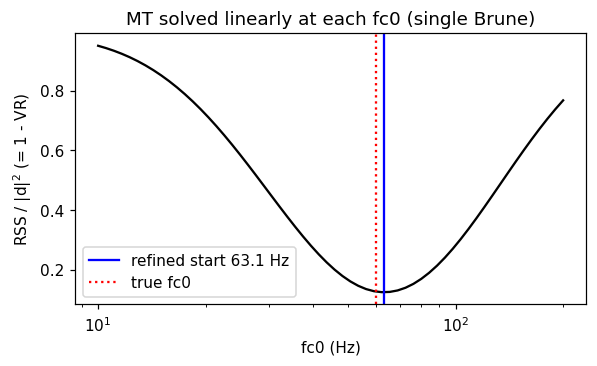

In [2]:
model = unshake.MTDCDirectivityModel()
tic = time.time()
p0 = model.find_non_linear_starting_model_params(ds)
print(f"variable projection: fc0 = {p0[6]:.2f} Hz in {time.time() - tic:.2f} s")

fc_scan = np.logspace(np.log10(10), np.log10(200), 60)
rss = []
for fc in fc_scan:
    p = model.find_non_linear_starting_model_params(ds, fc0=fc)
    rss.append(np.sum((ds.data - brune_synth(p[:6], fc)) ** 2))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogx(fc_scan, np.array(rss) / np.sum(ds.data ** 2), 'k')
ax.axvline(p0[6], color='b', label=f'refined start {p0[6]:.1f} Hz')
ax.axvline(60.0, color='r', ls=':', label='true fc0')
ax.set(xlabel='fc0 (Hz)', ylabel='RSS / |d|$^2$ (= 1 - VR)', title='MT solved linearly at each fc0 (single Brune)')
ax.legend();

## 2. Monte Carlo (prior sampling)

- Samples are drawn independently from the model prior:
  - a full MT on the unit sphere, times a fixed amplitude `scale`;
  - $\log f_{c0}$ uniform over `fc0_range`;
  - $\mathbf{v}$ isotropic Gaussian ($\sigma_v$ = 900 m/s), truncated at $|\mathbf{v}| \le$ 1600 m/s.
- Each sample is weighted by a Gaussian likelihood.
- `prepare` sets `scale` from the variable-projection MT. (LSQ on the formal GFs alone ignores the STF and underestimates the amplitude about 7-fold here.)
- The noise level is taken from the starting-model residual.
- **In 10-D, almost none of the samples land near the optimum.** The effective sample size is about 1, so the MC result is only a coarse search.

monte_carlo: no noise level given, using the starting-model residual std x sqrt(noise correlation factor 2.74) = 6.43e-13
Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)


monte_carlo: 50000 samples in 67.8 s
Result(MTDCDirectivityModel, n=50000, max VR=0.822, ESS=1.0)


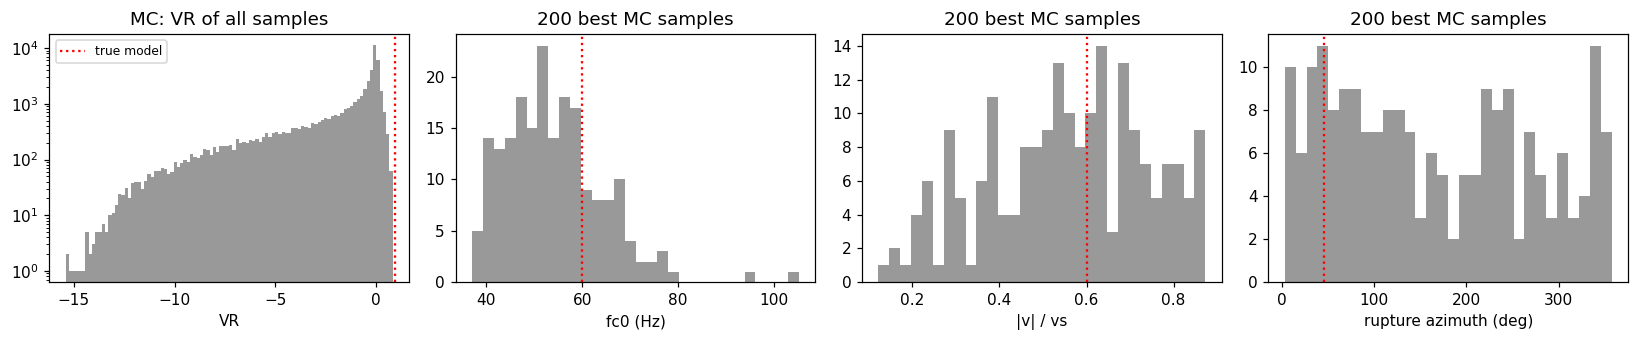

In [3]:
model_mc = unshake.MTDCDirectivityModel()
tic = time.time()
res_mc = unshake.monte_carlo(model_mc, ds, 50_000, rng=1)
t_mc = time.time() - tic
print(res_mc)
top = res_mc.top(200)
vr_mc, az_mc, pl_mc = model_mc.rupture(res_mc.params[top])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
axes[0].hist(res_mc.vr, 100, color='0.6')
axes[0].axvline(misfit.vr(ds.data, d_clean), color='r', ls=':', label='true model')
axes[0].set(xlabel='VR', title='MC: VR of all samples', yscale='log')
axes[0].legend(fontsize=8)
for ax, x, xt, lab in zip(axes[1:], (res_mc['fc0'][top], vr_mc / vs, az_mc),
                          (60.0, 0.6, 45.0), ('fc0 (Hz)', '|v| / vs', 'rupture azimuth (deg)')):
    ax.hist(x, 30, color='0.6')
    ax.axvline(xt, color='r', ls=':')
    ax.set(xlabel=lab, title='200 best MC samples')
plt.tight_layout()

## 3. Non-linear least squares

`unshake.nonlinear_least_squares(model, ds)` minimises $\tfrac12|\mathbf{r}|^2$, with:

$$\mathbf{r} = \Big[\tfrac{\sqrt{w_i}}{\sigma_i}\big(d_i - u_i(\mathbf{p})\big),\ \ \mathbf{v}/\sigma_v\Big]$$

- **Prior term.** The second term is the Gaussian prior on $\mathbf{v}$, which acts as damping. It keeps $\mathbf{v}$ determined where the data are not sensitive to it.
- **Solver.** `scipy.optimize.least_squares` (TRF) with finite bounds:
  - $|m_k| \le 3\,$`scale`;
  - $f_{c0}$ within `fc0_range`;
  - $|v_j| \le v_{max}$.
- **Conditioning.** `x_scale` puts every parameter at O(1): the MT in units of `scale`, $f_{c0}$ in units of its start value, $\mathbf{v}$ in units of $\sigma_v$.
- **Starts.** It starts from $\mathbf{p}_0$, plus 4 starts with $|\mathbf{v}| = \sigma_v/2$ in random directions.
- **Noise level.** With no noise level given, $\sigma$ is re-estimated as $\sigma^2 = \chi^2/(N - 10)$ at the optimum, and the fit is repeated once.
- **Uncertainty.** The Gauss–Newton covariance $(J^\mathsf{T}J)^{-1}$.
- **Correlated noise** (`correlated_noise=True`, the default).
  - The Gaussian likelihood treats every time sample as independent. The noise here is band-limited (2–210 Hz at 1 kHz sampling), so it has fewer independent samples, $n_{\rm eff} < n_t$.
  - $\sigma$ is therefore inflated by $\sqrt{n_t/n_{\rm eff}}$ and the fit repeated. The factor comes from the residual power spectrum $P(f)$: $n_t/n_{\rm eff} = n_f\sum P^2/(\sum P)^2$ (`misfit.noise_correlation_factor`). It is 1 for white noise and about 2.6 here.
  - Section 4 checks the corrected σ against repeated noise draws.

**Caveat:**
- **$v_U$ is set by the prior alone.** All receivers lie in the horizontal plane of the source, so $\mathbf{v}\cdot\hat r_i$ does not depend on $v_U$, and $v_U = 0 \pm \sigma_v$.

In [4]:
model_ls = unshake.MTDCDirectivityModel()
tic = time.time()
p_hat, cov, info = unshake.nonlinear_least_squares(model_ls, ds, rng=1)
t_ls = time.time() - tic
sd = np.sqrt(np.diag(cov))
print('costs of the starts:', np.round(info['start_costs'], 1))
pd.DataFrame({'true': p_true, 'start (VP)': model_ls.p0, 'NLLS': p_hat, 'GN 1 sigma': sd,
              '(NLLS - true) / sigma': (p_hat - p_true) / sd}, index=names).round(4)

Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)


nonlinear_least_squares: 5 start(s), 33 forward evaluations in 0.5 s; cost 2861, VR 0.9272, sigma 4.81e-13 (estimated), noise correlation factor 2.62
costs of the starts: [4391.1 4391.1 4391.1 4391.1 4391.1]


,true,start (VP),NLLS,GN 1 sigma,(NLLS - true) / sigma
Mnn,-0.0055,-0.0119,-0.0041,0.0130,0.1060
Mee,0.9461,0.9012,0.9439,0.0140,-0.1563
Mdd,-0.3406,-0.3634,-0.3643,0.0166,-1.4263
Mne,-0.1096,-0.1051,-0.1095,0.0023,0.0485
Mnd,-0.2679,-0.2616,-0.2717,0.0028,-1.3665
Med,0.2016,0.1896,0.2015,0.0027,-0.0357
fc0,60.0000,63.1267,59.9753,0.2510,-0.0983
v_e,772.1606,0.0000,745.0139,15.6915,-1.7300
v_n,772.1606,0.0000,762.7373,15.9117,-0.5922
v_u,-0.0000,0.0000,0.0000,900.0000,0.0000


In [5]:
# Rupture speed, azimuth and plunge, and lune position: draws from N(p_hat, cov) (no forward modelling)
draws = np.random.default_rng(2).multivariate_normal(p_hat, cov, 5000)
vr_d, az_d, pl_d = model_ls.rupture(draws)
vr_t, az_t, _ = (x[0] for x in model_ls.rupture(p_true))
g_d, de_d = np.degrees(mt.lune(draws[:, :6]))
g_t, de_t = np.degrees(mt.lune(m_true))
c_dc_d = mt.decompose(draws[:, :6])[2]
rows = {'|v| / vs (horizontal)': (np.hypot(draws[:, 7], draws[:, 8]) / vs, 0.6),
        'rupture azimuth (deg)': (az_d, az_t),
        'fc0 (Hz)': (draws[:, 6], 60.0),
        'lune gamma (deg)': (g_d, g_t), 'lune delta (deg)': (de_d, de_t),
        'DC fraction': (c_dc_d, c_dc)}
pd.DataFrame({k: {'true': t, 'median': np.median(x), '2.5 %': np.percentile(x, 2.5),
                  '97.5 %': np.percentile(x, 97.5)} for k, (x, t) in rows.items()}).T.round(3)

,true,median,2.5 %,97.5 %
|v| / vs (horizontal),0.600,0.586,0.567,0.605
rupture azimuth (deg),45.000,44.323,42.856,45.815
fc0 (Hz),60.000,59.971,59.478,60.479
lune gamma (deg),-6.587,-6.002,-6.457,-5.554
lune delta (deg),17.975,17.044,14.796,19.285
DC fraction,0.600,0.623,0.600,0.646


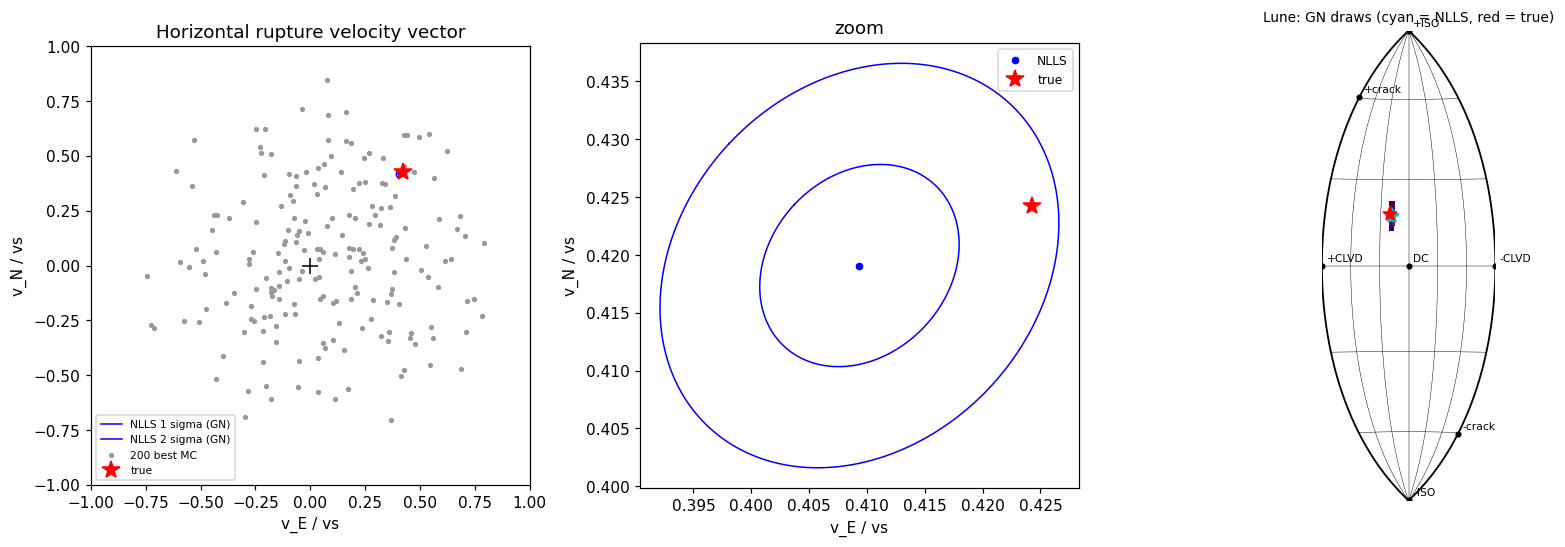

In [6]:
fig = plt.figure(figsize=(15, 5))
# (v_E, v_N): GN 1 and 2 sigma ellipses, best MC samples, truth
ax = fig.add_subplot(1, 3, 1)
C = cov[7:9, 7:9]
w_e, V_e = np.linalg.eigh(C)
th = np.linspace(0, 2 * np.pi, 200)
for k in (1, 2):
    ell = p_hat[7:9, None] + k * V_e @ (np.sqrt(w_e)[:, None] * np.vstack([np.cos(th), np.sin(th)]))
    ax.plot(ell[0] / vs, ell[1] / vs, 'b', lw=1, label=f'NLLS {k} sigma (GN)')
ax.scatter(res_mc.params[top, 7] / vs, res_mc.params[top, 8] / vs, s=6, c='0.6', label='200 best MC')
ax.plot(*(v_true[:2] / vs), 'r*', ms=12, label='true')
ax.plot(0, 0, 'k+', ms=10)
ax.set(xlabel='v_E / vs', ylabel='v_N / vs', aspect='equal', xlim=(-1, 1), ylim=(-1, 1),
       title='Horizontal rupture velocity vector')
ax.legend(fontsize=7, loc='lower left')
# zoom
ax = fig.add_subplot(1, 3, 2)
for k in (1, 2):
    ell = p_hat[7:9, None] + k * V_e @ (np.sqrt(w_e)[:, None] * np.vstack([np.cos(th), np.sin(th)]))
    ax.plot(ell[0] / vs, ell[1] / vs, 'b', lw=1)
ax.plot(*(p_hat[7:9] / vs), 'b.', ms=8, label='NLLS')
ax.plot(*(v_true[:2] / vs), 'r*', ms=12, label='true')
ax.set(xlabel='v_E / vs', ylabel='v_N / vs', aspect='equal', title='zoom')
ax.legend(fontsize=8)
# lune: GN draws, NLLS, truth
ax = fig.add_subplot(1, 3, 3)
plot.lune(m6=draws[:, :6], ax=ax, bins=(60, 120))
ax.plot(*plot._hammer(*mt.lune(p_hat[:6])), 'c*', ms=10)
ax.plot(*plot._hammer(*np.radians([g_t, de_t])), 'r*', ms=10)
ax.set_title('Lune: GN draws (cyan = NLLS, red = true)', fontsize=9)
plt.tight_layout()

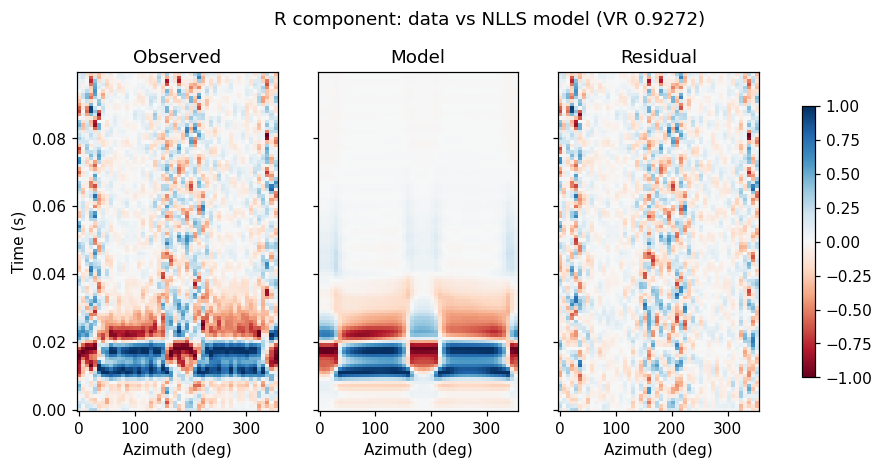

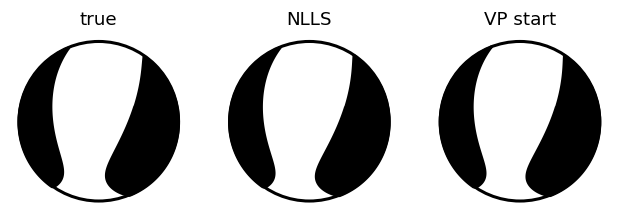

In [7]:
synth_ls = model_ls.forward(p_hat, ds)[0]
fig = plot.wavefield(comp(ds, 'R'), comp(make_ds(synth_ls), 'R').data, x=rec_az, xlabel='Azimuth (deg)')
fig.suptitle(f'R component: data vs NLLS model (VR {info["vr"]:.4f})', y=1.02)
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, (lab, m6) in zip(axes, (('true', m_true), ('NLLS', p_hat[:6]), ('VP start', model_ls.p0[:6]))):
    plot.beachball(m6, ax=ax)
    ax.set_title(lab)

## 4. Are the uncertainties right? Repeated noise draws

- NLLS is repeated on 30 new noise realisations of the same source, with one start each (about 30 s).
- The scatter of the 30 estimates is the actual uncertainty. It is compared with the mean GN σ:
  - without the correlated-noise correction (`correlated_noise=False`);
  - with it.
- With 30 runs, the scatter itself is uncertain by about ±13 %.

In [8]:
import contextlib, io
est, sd_white, sd_corr = [], [], []
for k in range(30):
    ds_k = make_ds(add_noise(d_clean, np.random.default_rng(100 + k)))
    with contextlib.redirect_stdout(io.StringIO()):            # silence the per-run summaries
        p_k, cov_w, _ = unshake.nonlinear_least_squares(unshake.MTDCDirectivityModel(), ds_k, n_starts=0,
                                                        correlated_noise=False)
        _, cov_k, _ = unshake.nonlinear_least_squares(unshake.MTDCDirectivityModel(), ds_k, n_starts=0)
    est.append(p_k)
    sd_white.append(np.sqrt(np.diag(cov_w)))
    sd_corr.append(np.sqrt(np.diag(cov_k)))
tab_sd = pd.DataFrame({'scatter of 30 estimates': np.std(est, axis=0),
                       'GN sigma, white noise': np.mean(sd_white, axis=0),
                       'GN sigma, corrected': np.mean(sd_corr, axis=0)}, index=names)
tab_sd['scatter / white'] = tab_sd.iloc[:, 0] / tab_sd.iloc[:, 1]
tab_sd['scatter / corrected'] = tab_sd.iloc[:, 0] / tab_sd.iloc[:, 2]
tab_sd.drop('v_u').round(4)                                  # v_u: prior only (no data sensitivity)

,scatter of 30 estimates,"GN sigma, white noise","GN sigma, corrected",scatter / white,scatter / corrected
Mnn,0.0129,0.0081,0.0130,1.6034,0.9941
Mee,0.0143,0.0087,0.0140,1.6455,1.0202
Mdd,0.0164,0.0103,0.0165,1.5995,0.9916
Mne,0.0028,0.0014,0.0023,1.9368,1.2008
Mnd,0.0022,0.0017,0.0027,1.3127,0.8138
Med,0.0032,0.0017,0.0027,1.9252,1.1936
fc0,0.2509,0.1556,0.2510,1.6118,0.9993
v_e,13.4383,9.9140,15.9890,1.3555,0.8405
v_n,14.2247,9.9826,16.0997,1.4249,0.8835


## 5. MCMC: adaptive Metropolis

`unshake.mcmc(model, ds, p_hat, cov, sigma=info['sigma'])` samples the full posterior.

$$\log p(\mathbf{p}\,|\,\mathbf{d}) = \log L(\mathbf{d}\,|\,\mathbf{p}) + \log p(\mathbf{p}) + \text{const}$$

- **Likelihood.** The same Gaussian likelihood as NLLS, with the σ already inflated for correlated noise.
- **Prior.** `MTDCDirectivityModel.log_prior` combines:
  - a flat prior on the MT within the bounds;
  - log-uniform $f_{c0}$;
  - the truncated Gaussian on $\mathbf{v}$.
- **Proposals.**
  - 8 chains start at draws from the NLLS Gaussian.
  - Each step proposes a Gaussian jump for every chain, scaled $2.38^2/10$ times the covariance (the optimal scale for a Gaussian target).
  - All chains are evaluated in one batched forward call.
- **Adaptation.** During burn-in (the first half), the covariance is re-estimated from the chains every 100 steps. After that it is fixed.
- **Diagnostics:**
  - acceptance rate (about 0.23 is optimal in high dimensions);
  - Gelman–Rubin R-hat (< 1.05);
  - effective sample size, from the autocorrelation time.
- **No gradients are needed.**

Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)


mcmc: 8 chains x 4000 steps (burn-in 2000) in 32.1 s; acceptance 0.25, max R-hat 1.011, min ESS 441
Result(MTDCDirectivityModel, n=16000, max VR=0.927, ESS=440.9)


,true,NLLS,GN sigma,MCMC mean,MCMC std,R-hat,autocorr. time (steps)
Mnn,-0.0055,-0.0041,0.0130,-0.0028,0.0134,1.0068,30.7361
Mee,0.9461,0.9439,0.0140,0.9451,0.0146,1.0049,31.9452
Mdd,-0.3406,-0.3643,0.0166,-0.3628,0.0168,1.0087,30.8325
Mne,-0.1096,-0.1095,0.0023,-0.1097,0.0023,1.0098,36.1467
Mnd,-0.2679,-0.2717,0.0028,-0.2718,0.0028,1.0032,34.5420
Med,0.2016,0.2015,0.0027,0.2015,0.0026,1.0081,33.4830
fc0,60.0000,59.9753,0.2510,59.9687,0.2414,1.0066,36.2913
v_e,772.1606,745.0139,15.6915,745.2249,15.3089,1.0053,29.3570
v_n,772.1606,762.7373,15.9117,762.5060,16.3471,1.0113,34.0367
v_u,-0.0000,0.0000,900.0000,60.8898,596.9367,1.0080,25.9640


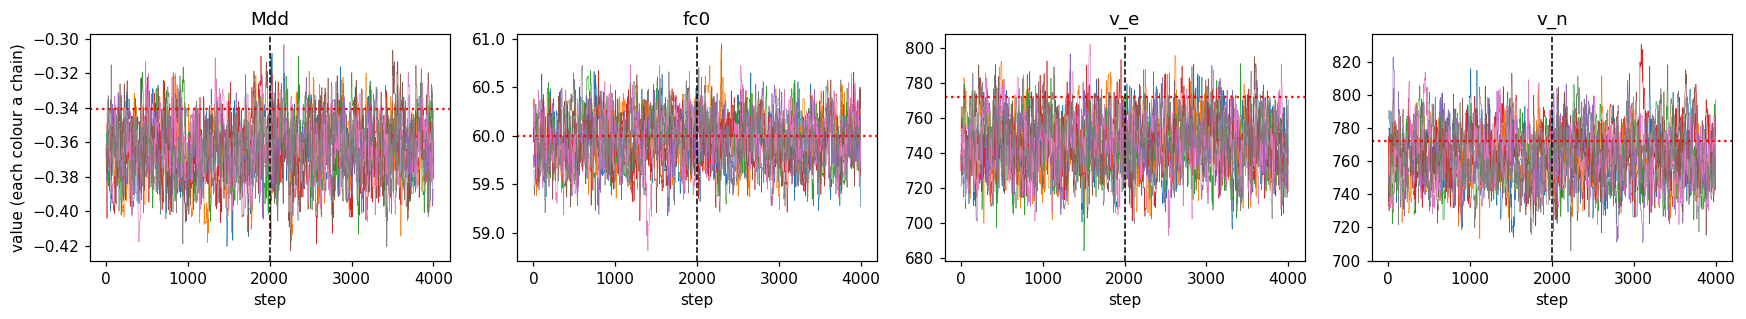

In [9]:
tic = time.time()
res_mcmc = unshake.mcmc(model_ls, ds, p_hat, cov, n_steps=4000, n_chains=8, sigma=info['sigma'], rng=3)
t_mcmc = time.time() - tic
print(res_mcmc)
chain, burn = res_mcmc.meta['chain'], res_mcmc.meta['burn']

fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharex=True)
for ax, j in zip(axes, (2, 6, 7, 8)):
    ax.plot(chain[:, :, j], lw=0.4)
    ax.axvline(burn, color='k', ls='--', lw=1)
    ax.axhline(p_true[j], color='r', ls=':')
    ax.set(title=names[j], xlabel='step')
axes[0].set_ylabel('value (each colour a chain)')
plt.tight_layout()

pd.DataFrame({'true': p_true, 'NLLS': p_hat, 'GN sigma': sd, 'MCMC mean': res_mcmc.mean,
              'MCMC std': res_mcmc.params.std(axis=0), 'R-hat': res_mcmc.meta['rhat'],
              'autocorr. time (steps)': res_mcmc.meta['tau']}, index=names).round(4)

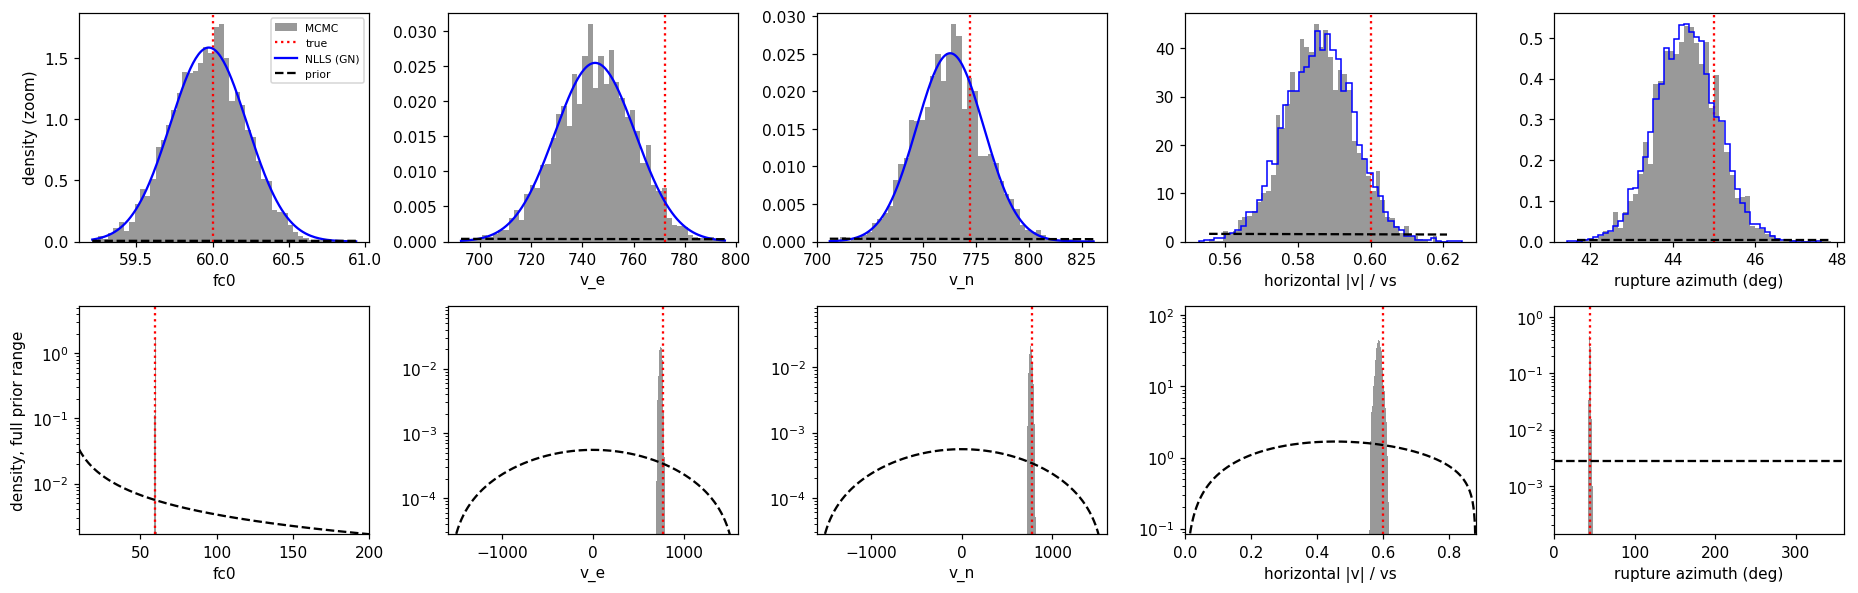

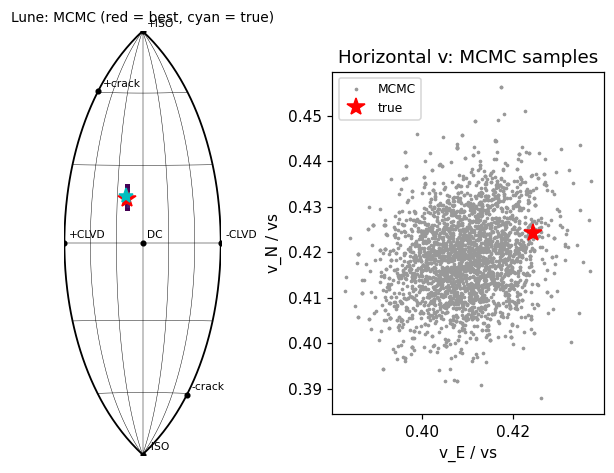

In [10]:
# Marginals: MCMC histograms (grey) vs the NLLS Gauss-Newton Gaussian (blue) and the prior (black dashed).
# Top row: zoomed on the posterior. Bottom row: the full prior support, log density.
from scipy.stats import chi2, norm
vr_m, az_m, _ = model_ls.rupture(res_mcmc.params)
sig_v, v_max = model_ls.sigma_v, model_ls.v_max
z_v = chi2.cdf((v_max / sig_v) ** 2, 3)                     # P(|v| <= v_max) of the untruncated Gaussian

def prior_pdf(j, x):
    """Marginal prior density (as in model.log_prior) of fc0 (j = 6) or one component of v (j = 7, 8, 9)."""
    if j == 6:                                              # log-uniform over fc0_range
        lo, hi = model_ls.fc0_range
        return np.where((x >= lo) & (x <= hi), 1.0 / (x * np.log(hi / lo)), 0.0)
    r2 = np.clip(v_max ** 2 - x ** 2, 0.0, None)            # the other two components must fit in the ball
    return norm.pdf(x, 0.0, sig_v) * (1.0 - np.exp(-0.5 * r2 / sig_v ** 2)) / z_v

def prior_pdf_vh(x):
    """Prior density of the horizontal speed |(v_E, v_N)| / vs."""
    h = x * vs
    r = np.sqrt(np.clip(v_max ** 2 - h ** 2, 0.0, None))   # room left for v_U
    return vs * h / sig_v ** 2 * np.exp(-0.5 * (h / sig_v) ** 2) * (2.0 * norm.cdf(r / sig_v) - 1.0) / z_v

# (posterior samples, GN draws or None, GN pdf or None, prior pdf, full prior range, true value, label)
panels = [(res_mcmc.params[:, j], None, lambda xx, j=j: norm.pdf(xx, p_hat[j], sd[j]),
           lambda xx, j=j: prior_pdf(j, xx), rng_j, p_true[j], names[j])
          for j, rng_j in ((6, model_ls.fc0_range), (7, (-v_max, v_max)), (8, (-v_max, v_max)))]
panels += [(np.hypot(*res_mcmc.params[:, 7:9].T) / vs, np.hypot(draws[:, 7], draws[:, 8]) / vs, None,
            prior_pdf_vh, (0.0, v_max / vs), 0.6, 'horizontal |v| / vs'),
           (az_m, az_d, None, lambda a: np.full_like(a, 1.0 / 360.0),   # isotropic prior: uniform azimuth
            (0.0, 360.0), az_t, 'rupture azimuth (deg)')]

fig, axes = plt.subplots(2, 5, figsize=(17, 5.5))
for (ax, ax_f), (x, xd, gn, pr, (lo, hi), xt, lab) in zip(axes.T, panels):
    xx = np.linspace(x.min(), x.max(), 200)
    for a in (ax, ax_f):
        dens = a.hist(x, 50, density=True, color='0.6', label='MCMC')[0]
        a.axvline(xt, color='r', ls=':', label='true')
        a.set(xlabel=lab)
    if xd is not None:
        ax.hist(xd, 50, density=True, histtype='step', color='b', label='NLLS (GN)')
    if gn is not None:
        ax.plot(xx, gn(xx), 'b', label='NLLS (GN)')
    ax.plot(xx, pr(xx), 'k--', label='prior')
    xx_f = np.linspace(lo, hi, 1000)                        # full prior support (GN omitted: it matches MCMC)
    p_f = pr(xx_f)
    ax_f.plot(xx_f, p_f, 'k--')
    ax_f.set(xlim=(lo, hi), yscale='log', ylim=(0.05 * p_f.max(), 3.0 * max(dens.max(), p_f.max())))
axes[0, 0].legend(fontsize=7)
axes[0, 0].set_ylabel('density (zoom)')
axes[1, 0].set_ylabel('density, full prior range')
plt.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(7, 5))
plot.lune(result=res_mcmc, ax=axes[0], bins=(60, 120))
axes[0].plot(*plot._hammer(*np.radians([g_t, de_t])), 'c*', ms=10)
axes[0].set_title('Lune: MCMC (red = best, cyan = true)', fontsize=9)
axes[1].scatter(*res_mcmc.params[::5, 7:9].T / vs, s=2, c='0.6', label='MCMC')
axes[1].plot(*(v_true[:2] / vs), 'r*', ms=12, label='true')
axes[1].set(xlabel='v_E / vs', ylabel='v_N / vs', aspect='equal', title='Horizontal v: MCMC samples')
axes[1].legend(fontsize=8);

## 6. Checks: noise-free data, and a source with no DC part
- **Noise-free data.** NLLS should recover the true parameters almost exactly.
- **Pure tensile crack** (eigenvalues 3:1:1, $C_{DC} = 0$). The true source has no DC part, so the true $\mathbf{v}$ has no effect on the data.
  - The noise lets the estimated MT pick up a small spurious DC part (below 1 %). That gives $\mathbf{v}$ a weak, noise-driven sensitivity.
  - Expect a $\mathbf{v}$ that is not significant (within about 2σ of 0) and loosely constrained (σ a sizeable fraction of the prior $\sigma_v$).
  - With $C_{DC} \approx 0$, the recovered $\mathbf{v}$ should not be interpreted.
  - MCMC shows this directly: the posterior of $|\mathbf{v}|$ is close to its prior.

Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)


nonlinear_least_squares: 5 start(s), 38 forward evaluations in 0.6 s; cost 0.7361, VR 1.0000, sigma 4.28e-17 (estimated), noise correlation factor 2.84
noise-free: max |NLLS - true| / |true|: MT 5.491290441242522e-13  fc0 3.2223113066720544e-13  v 3.0576996376301052e-12
Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)


nonlinear_least_squares: 5 start(s), 57 forward evaluations in 0.9 s; cost 2900, VR 0.9494, sigma 2.27e-13 (estimated), noise correlation factor 2.59
crack: DC fraction of the estimate 0.007; fc0 60.22 Hz; v = [-484.  634.    0.] +/- [577. 622. 900.] m/s (prior sigma_v = 900)
Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)


mcmc: 8 chains x 3000 steps (burn-in 1500) in 20.7 s; acceptance 0.25, max R-hat 1.046, min ESS 293


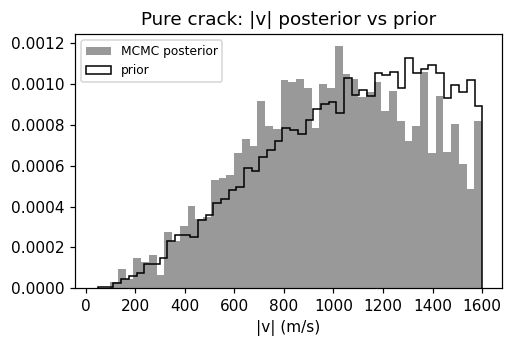

In [11]:
p_nf, cov_nf, _ = unshake.nonlinear_least_squares(unshake.MTDCDirectivityModel(), make_ds(d_clean), rng=1)
print('noise-free: max |NLLS - true| / |true|: MT', np.abs(p_nf[:6] - m_true).max() / mt.norm(m_true),
      ' fc0', abs(p_nf[6] - 60) / 60, ' v', np.linalg.norm(p_nf[7:] - v_true) / np.linalg.norm(v_true))

m_crack = mt.from_33(V_axes @ np.diag([3.0, 1.0, 1.0]) @ V_axes.T) / 3.0
p_crack = np.r_[m_crack, 60.0, v_true]
d_crack = add_noise(unshake.MTDCDirectivityModel(scale=1.0).forward(p_crack, ds_gf)[0], np.random.default_rng(3))
model_c = unshake.MTDCDirectivityModel()
p_c, cov_c, info_c = unshake.nonlinear_least_squares(model_c, make_ds(d_crack), rng=1)
print(f"crack: DC fraction of the estimate {mt.decompose(p_c[:6])[2]:.3f}; fc0 {p_c[6]:.2f} Hz; "
      f"v = {np.round(p_c[7:])} +/- {np.round(np.sqrt(np.diag(cov_c))[7:])} m/s (prior sigma_v = 900)")
res_c = unshake.mcmc(model_c, make_ds(d_crack), p_c, cov_c, n_steps=3000, sigma=info_c['sigma'], rng=4)
v_prior = model_c.sample_prior(20000, 0)[:, 7:10]
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(np.linalg.norm(res_c.params[:, 7:10], axis=1), 50, density=True, color='0.6', label='MCMC posterior')
ax.hist(np.linalg.norm(v_prior, axis=1), 50, density=True, histtype='step', color='k', label='prior')
ax.set(xlabel='|v| (m/s)', title='Pure crack: |v| posterior vs prior')
ax.legend(fontsize=8);

## 7. Comparison

In [12]:
def summary(p):
    vr_, az_, _ = (x[0] for x in model_ls.rupture(p))
    return p[6], vr_ / vs, az_, float(misfit.vr(ds.data, model_ls.forward(p, ds)[0]))
rows = {'true': summary(p_true), 'VP start (v = 0)': summary(model_ls.p0),
        'MC best of 50k': summary(res_mc.best), 'NLLS': summary(p_hat), 'MCMC mean': summary(res_mcmc.mean)}
tab = pd.DataFrame(rows, index=['fc0 (Hz)', '|v| / vs', 'azimuth (deg)', 'VR']).T
tab['time (s)'] = [np.nan, np.nan, t_mc, t_ls, t_mcmc]
tab['forward evals'] = [np.nan, np.nan, 50_000, info['nfev'], res_mcmc.meta['n_steps'] * res_mcmc.meta['n_chains']]
tab['ESS'] = [np.nan, np.nan, res_mc.ess, np.nan, res_mcmc.ess]
tab.round(3)

,fc0 (Hz),|v| / vs,azimuth (deg),VR,time (s),forward evals,ESS
true,60.000,0.600,45.000,0.927,NaN,NaN,NaN
VP start (v = 0),63.127,0.000,0.000,0.876,NaN,NaN,NaN
MC best of 50k,70.694,0.433,235.399,0.822,67.910,50000.0,1.000
NLLS,59.975,0.586,44.327,0.927,0.561,33.0,NaN
MCMC mean,59.969,0.587,44.343,0.927,32.161,32000.0,440.877


**Summary:**
- **Variable projection** gives a good starting $f_{c0}$ and MT cheaply. With directivity in the data its $f_{c0}$ is biased by a few Hz, because one Brune has to fit both the forward and backward directions.
- **Plain prior-sampling MC is a poor tool in 10-D.** Even 50k samples (about 40 s) leave an ESS of about 1, and the best sample is far from the optimum.
- **NLLS converges in under a second**, a few tens of forward evaluations per start, and recovers the MT, $f_{c0}$ and the horizontal $\mathbf{v}$. The multi-starts all reach the same minimum here.
- **The GN covariance is a quick local uncertainty.** With the correlated-noise correction it matches the scatter over repeated noise draws (section 4). Without it, it is about 1.6× too small.
- **MCMC gives the full posterior** in a few tens of seconds, with an ESS of a few hundred. Here it agrees with the GN Gaussian, because the posterior is close to Gaussian. It also respects the prior, e.g. the ball $|\mathbf{v}| \le v_{max}$, and shows non-Gaussian posteriors where NLLS cannot (the crack).
- **For sources with little DC**, $\mathbf{v}$ is not constrained by the data (section 6). Report it together with $C_{DC}$.

**Possible improvements:**
- HMC/NUTS (NumPyro, PyMC), which needs a differentiable forward model;
- whitening the data by the noise spectrum, in place of the scalar correlated-noise factor.